In [7]:
import obspy
from obspy import read
from geopy.distance import geodesic
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime
from obspy.signal.filter import lowpass
from obspy.clients.fdsn.client import Client
import json
import scipy
import xarray as xr
from matplotlib.colors import LightSource
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
import matplotlib
import glob
from matplotlib import colors
from pyproj import Proj
from geopy.distance import geodesic
import pickle
import matplotlib.animation as animation
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 14}) 
from math import radians, cos, sin, atan2, sqrt, degrees
import imageio
from itertools import product
import dask
from dask.diagnostics import ProgressBar
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)

In [8]:
scenario = 'buried-locking-mur13-deep'

In [13]:
path = '/Volumes/Extreme Pro/cascadia_2025_synthetics'
offshore_st_path = glob.glob(path + '/audrey_offshore_stations/*')[0]
pnsn_st_path = glob.glob(path + '/audrey_broadband_pnsngrid/*')[0]

In [16]:
offshore_st = read(offshore_st_path)
pnsn_st = read(pnsn_st_path)
all_st = offshore_st+pnsn_st

3159 Trace(s) in Stream:

CZ.CZSB1..N | 1970-01-01T00:00:00.000253Z - 1970-01-01T00:06:35.000253Z | 8.0 Hz, 3161 samples
...
(3157 other traces)
...
UW.SKIT..N | 1970-01-01T00:00:00.000247Z - 1970-01-01T00:06:35.000247Z | 8.0 Hz, 3161 samples

[Use "print(Stream.__str__(extended=True))" to print all Traces]


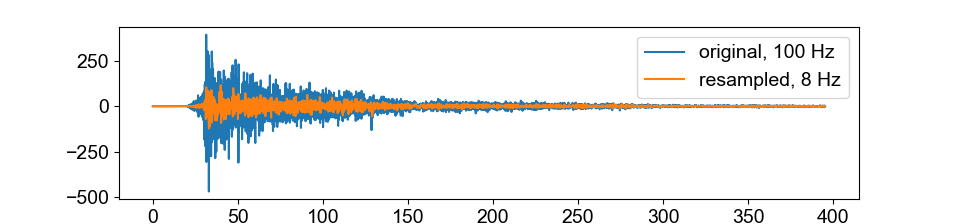

In [20]:
%matplotlib widget

fig,ax = plt.subplots(1,figsize=[9.54, 2.24])
ax.plot(all_st[0].times(),all_st[0].data,label='original, 100 Hz')

st2 = all_st.copy()
t1 = st2[0].stats.starttime
t2 = st2[0].stats.endtime
st2.trim(t1-5,t2+5,fill_value=np.int32(np.mean(st2[0].data)),pad=True)

st2.resample(8.0,no_filter=False)
st2.trim(t1,t2)
print(st2)

ax.plot(st2[0].times(),st2[0].data,label='resampled, 8 Hz')

ax.legend()

In [21]:
networks = []
stations = []
channels = []
lats = []
lons = []
max_raw_amp = []
median_raw_amp = []
max_ds_amp = []
median_ds_amp = []

In [22]:
for i in range(len(all_st)):
    tr = all_st[i]

    # Get original amplitudes
    max_raw_amp.append(np.max(np.abs(tr.data)))
    median_raw_amp.append(np.mean(tr.data))

    # Now downsample
    st2 = tr.copy()
    t1 = st2.stats.starttime
    t2 = st2.stats.endtime
    st2.trim(t1-5,t2+5,fill_value=np.int32(np.mean(st2.data)),pad=True) # pad ends so we can cut off edge effects
    st2.resample(8.0,no_filter=False)
    st2.trim(t1,t2) # cut off edge effects

    # Get downsampled amplitudes
    max_ds_amp.append(np.max(np.abs(st2.data)))
    median_ds_amp.append(np.mean(st2.data))

In [23]:
amp_ratio = [max_ds_amp[i]/max_raw_amp[i] for i in range(len(max_ds_amp))]

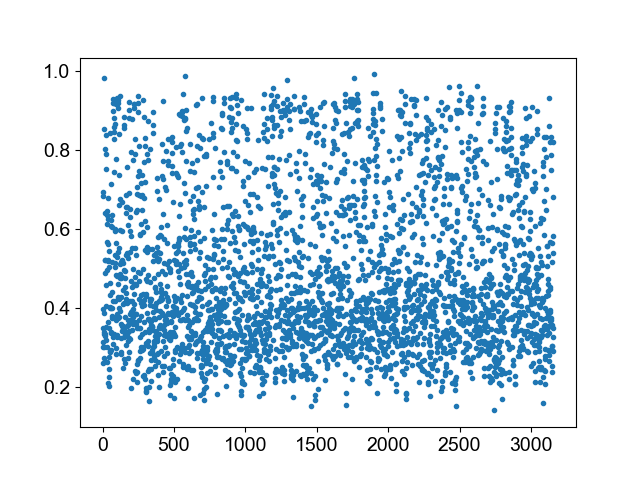

In [25]:
fig,ax = plt.subplots(1)
ax.plot(amp_ratio,'.')